# Weather and the spreading plan: which fertilizer, when

`integration.ipynb` answers **how much**: an annual Mg and N dose per zone, and how many kg of each product that is.
This notebook answers **when**, from the weather rules the backend and the app already run (`weather/krops_rules.py`):

| Part | Question | Rule |
|---|---|---|
| 1 | What did the drone run recommend? | the output of `integration.ipynb` |
| 2 | Has the plot had enough rain lately? | **L5**: P30 (rain in the last 30 days) under 60 mm → `water_stress` (decided) |
| 3 | Is this month a spreading month? | **L8 Stage A**: the 1991–2020 average rain of the month → `open`, `cek` or `tunda` |
| 4 | Which of the next 10 days are safe? | **L8 Stage B**: the forecast without days over 25 mm, the day before them, and the last day |
| 5 | What to spread on which day, this round | this notebook: half the annual dose; N 14 days after dolomite, or the next safe day after kieserite |
| 6 | When are the two rounds in a year? | this notebook: two open months 6 months apart (GUESS) |

**Data and API calls per run.** Responses are saved in `weather/data/raw/` and reused (a forecast or recent rain only
on the same day), so a second run on the same day makes no calls.

| Data point | Source | Calls per run |
|---|---|---|
| Zone doses (Mg, N, product kg) | `oil_palm_zones_vari.json` and `oil_palm_zone_fertilizer_product_mass.csv` from `integration.ipynb` | 0 |
| 10-day rain forecast | Apple WeatherKit, daily forecast | 1 |
| Daily rain since the 1st of last month | Apple WeatherKit, daily history (10 days per request) | 5–8 |
| Same days, the fallback | NASA POWER daily rain (free) | 1 |
| 1991–2020 daily rain (month table, normals) | NASA POWER, saved once and reused forever | 0 once saved |

The site comes from `weather/.env` (`SITE_NAME`, `LAT`, `LON`). Its coordinates are never printed here.

Constants marked `GUESS – no source yet` are this notebook's own proposals and need an agronomist's confirmation. The
L5 and L8 thresholds are the team's (decided or proposal, as written in `krops_rules.py`).

## Setup

In [1]:
import json
import sys
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path("../weather").resolve()))
import krops_rules as rules
import krops_weather as kw
from krops_weather import SITE_NAME, TODAY, WK_READY

kw.use_chart_style()
pd.set_option("display.width", 160)
print(f"{SITE_NAME} · today {TODAY} · WeatherKit credentials: {'yes' if WK_READY else 'no'}")
if not WK_READY:
    raise RuntimeError("WeatherKit credentials missing in weather/.env: the forecast and P30 need them")

Tanjung Pinang · today 2026-10-26 · WeatherKit credentials: yes


## Configuration
**What:** the inputs from the integration run, this notebook's outputs, and the spreading constants.

**Why GUESS:** no rule in the repo says how many rounds a year, or how far apart N and Mg go. These are common
practice for smallholders (two or three rounds a year), not a team decision.

In [ ]:
ZONES_JSON = "oil_palm_zones_vari.json"                      # from integration.ipynb
PRODUCT_MASS_CSV = "oil_palm_zone_fertilizer_product_mass.csv"  # from integration.ipynb
OUTPUT_PLAN_CSV = "oil_palm_spreading_plan.csv"
OUTPUT_RAIN_PLOT = "oil_palm_spreading_rain.png"
OUTPUT_CALENDAR_PLOT = "oil_palm_spreading_calendar.png"

ROUNDS_PER_YEAR = 2              
ROUND_GAP_MONTHS = 6             
# Dolomite is a lime: it raises the pH near its particles, which increases ammonia loss from urea and ammonium N. 
# Practice is at least 2 weeks (14–28 days); there is no peer-reviewed or PPKS/MPOB number. 
# Kieserite doesn't change pH: 1 day only keeps N and Mg apart
MIN_DAYS_MG_TO_N = {"dolomite_Mg_cheaper": 14, "kieserite_Mg_expensive": 1}
NORMAL_PERIOD = rules.NORMAL_PERIOD  # 1991–2020, the Stage A table (proposed)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# One line per product, shown with the plan. GUESS – no source yet: general agronomy, to be checked by an agronomist.
PRODUCT_NOTES = {
    "kieserite_Mg_expensive": "Kieserite (MgSO4): water-soluble, acts within weeks; the faster Mg option.",
    "dolomite_Mg_cheaper": "Dolomite (Ca/Mg carbonate): slow, also raises soil pH (suits acid soils); spread N at "
                           "least 14 days after it (MIN_DAYS_MG_TO_N), never together.",
    "ZA_N_cheaper": "ZA (ammonium sulfate): acidifies the soil over time; next to fresh dolomite its ammonium is "
                    "lost to the air as well.",
    "urea_N_expensive": "Urea: highest N content, but loses N to the air on hot, dry soil left uncovered, and more "
                        "on soil limed with dolomite; spread on moist soil before light rain.",
}

## 1. What the drone run recommended
**In:** the integration outputs · **Out:** `zones` (per zone: trees, boost, annual elemental Mg and N, confidence and
flags) and `products` (kg of each product per zone and per palm, per year).

Run `integration.ipynb` first: this notebook only reads its files.

In [3]:
for path in (ZONES_JSON, PRODUCT_MASS_CSV):
    if not Path(path).exists():
        raise FileNotFoundError(f"{path} not found: run integration.ipynb first")
run = json.loads(Path(ZONES_JSON).read_text())
products = pd.read_csv(PRODUCT_MASS_CSV)


def annual_nutrient_kg(zone, nutrient):
    """Elemental kg a year for one nutrient; every product of that nutrient carries the same amount."""
    items = [f for f in zone["recommendation"]["fertilizers"].values() if f["recommended_nutrient"] == nutrient]
    return items[0]["annual_total_kg"] if items else None


zones = pd.DataFrame([{
    "zone": f"Z{z['zone_id']}",
    "trees": z["tree_count"],
    "boost": z["recommendation"]["boost_fraction"],
    "Mg kg/year": annual_nutrient_kg(z, "Mg"),
    "N kg/year": annual_nutrient_kg(z, "N"),
    "confidence": z["confidence"]["confidence"],
    "may be less accurate": z["confidence"]["may_be_less_accurate"],
} for z in run["zones"]]).set_index("zone")
products["zone"] = "Z" + products["zone_id"].astype(str)
print(f"Photo: {Path(run['metadata']['source_image']).name} · {len(zones)} zones · {int(zones['trees'].sum())} trees")
display(zones.style.format({"boost": "{:.1%}", "Mg kg/year": "{:.3f}", "N kg/year": "{:.3f}", "confidence": "{:.2f}"}))

Photo: dji_10.jpg · 5 zones · 34 trees


,trees,boost,Mg kg/year,N kg/year,confidence,may be less accurate
zone,,,,,,
Z1,9,10.3%,0.204,1.344,0.60,True
Z2,6,10.8%,0.143,0.940,0.49,True
Z3,9,0.0%,0.000,0.000,0.60,True
Z4,9,5.4%,0.108,0.711,0.60,True
Z5,1,6.4%,0.014,0.092,0.20,True


## 2. L5: has the plot had enough rain lately?
**What:** P30, the rain of the 30 days ending on the latest day with data, from WeatherKit's daily history first and
NASA POWER as the fallback. NASA POWER months that are implausibly wet (over 3 × both their 1991–2020 normal and
WeatherKit) or have too few days are dropped first (`rules.suspect_months`, `rules.unchecked_months`). This is the
backend's rule, unchanged (`rules.choose_p30`).

**Why it matters for spreading:** in a dry spell fertilizer sits on the surface and the palm can't take it up. Under
60 mm the plan below says *wait for rain* instead of giving dates.

**In:** WeatherKit and NASA POWER daily rain · **Out:** `p30` (the L5 record), `water_stress`.

In [4]:
first = (TODAY - timedelta(days=45)).replace(day=1)  # the 1st of last month: the monthly check needs whole months
wk_recent = kw.fetch_weatherkit_history(first, TODAY - timedelta(days=1))["rain_mm"]
nasa_recent = kw.fetch_nasa_power(first, TODAY, params=("PRECTOTCORR",))[0]["PRECTOTCORR"]
nasa_history = kw.fetch_nasa_power(date(1991, 1, 1), date(2025, 12, 31), params=("PRECTOTCORR",))[0]["PRECTOTCORR"]

as_dict = lambda s: {d: (None if pd.isna(v) else float(v)) for d, v in s.items()}
wk_daily, nasa_daily, history_daily = as_dict(wk_recent), as_dict(nasa_recent), as_dict(nasa_history)
normals = rules.monthly_normals(history_daily, *NORMAL_PERIOD)
dropped = rules.suspect_months(nasa_daily, normals, wk_daily) | rules.unchecked_months(nasa_daily)
nasa_checked = rules.drop_months(nasa_daily, dropped)

p30 = rules.choose_p30({"weatherkit-history": wk_daily, "nasa-power": nasa_checked}, TODAY)
water_stress = p30["water_stress"]
print(f"NASA POWER months dropped by the check: {sorted(f'{y}-{m:02d}' for y, m in dropped) or 'none'}")
if p30["p30_mm"] is None:
    print(f"P30 unknown: no source has a full 30-day window ending within {rules.P30_MAX_AGE_DAYS} days "
          f"(missing days {p30['p30_missing_days']})")
else:
    print(f"P30 = {p30['p30_mm']} mm, {p30['p30_start_date']} to {p30['p30_end_date']} · source {p30['p30_source']} "
          f"({p30['p30_quality']}) · water_stress: {water_stress}")

NASA POWER months dropped by the check: ['2026-09', '2026-10']
P30 = 115.0 mm, 2026-09-26 to 2026-10-25 · source weatherkit-history (ok) · water_stress: False


## 3. L8 Stage A: is this month a spreading month?
**What:** the average rain of each calendar month over 1991–2020 (NASA POWER), and its gate:

| Month average | Gate | Meaning |
|---|---|---|
| under 60 mm or over 300 mm | `tunda` | wait: too dry to dissolve, or so wet it washes away (proposal) |
| 60 to under 100 mm | `cek` | check soil and weather first (decided 9 Oct) |
| 100–300 mm | `open` | go to Stage B (100–200 proposal, 200–300 decided 9 Oct) |

The in-band share (how many years the month fell in 100–200 mm) is logged only, by decision; part 6 uses it to rank
months.

**In:** 1991–2020 daily rain · **Out:** `month_table` (avg mm, in-band share and gate per month).

In [5]:
table = rules.month_table(history_daily, *NORMAL_PERIOD)
month_table = pd.DataFrame(table).T
month_table["gate"] = [rules.month_gate(v) for v in month_table["avg_mm"]]
month_table.index = MONTHS
display(month_table.style.format({"avg_mm": "{:.0f}", "in_band_share": "{:.0%}"}))
print(f"This month ({MONTHS[TODAY.month - 1]}): {month_table.iloc[TODAY.month - 1]['gate']}")

,avg_mm,in_band_share,gate
Jan,216,40%,open
Feb,108,37%,open
Mar,172,37%,open
Apr,205,43%,open
May,207,40%,open
Jun,174,70%,open
Jul,173,43%,open
Aug,168,57%,open
Sep,163,60%,open
Oct,210,33%,open


This month (Oct): open


## 4. L8 Stage B: which of the next 10 days are safe?
**What:** the WeatherKit 10-day forecast goes through `rules.l8_decision`, the same function the app runs. It removes
days over 25 mm (proposal), the day before each of them (decided 9 Oct: fertilizer spread then is still on the surface
when the storm comes), and the last cached day (nothing to check it against). With the closed-month cut on, days in a
later month whose gate isn't open go too.

**In:** the forecast, `table`, today · **Out:** `l8` with `l8_state`: `jendela_tabur` (dates), `tunda`, `cek` or
`cek_hujan` (no safe day left).

In [6]:
forecast_df = kw.tidy_weatherkit_days(kw.fetch_weatherkit_daily())
forecast = {d: (None if pd.isna(v) else float(v)) for d, v in zip(forecast_df["date"], forecast_df["rain_mm"])}
l8 = rules.l8_decision(forecast, table, TODAY)
safe_days = l8["dates"]
display(forecast_df[["date", "rain_mm", "rain_chance"]].assign(
    safe=[d in safe_days for d in forecast_df["date"]]).set_index("date"))
print(f"L8 state: {l8['l8_state']}")
if l8["removed"]:
    for reason, days in l8["removed"].items():
        print(f"  removed ({reason}): {', '.join(f'{d:%a %d %b}' for d in days) or 'none'}")
print("Safe days:", ", ".join(f"{d:%a %d %b}" for d in safe_days) or "none")

,rain_mm,rain_chance,safe
date,,,
2026-10-26,5.97,0.91,True
2026-10-27,2.53,0.57,True
2026-10-28,14.99,0.84,True
2026-10-29,11.61,0.87,True
2026-10-30,4.36,0.70,True
2026-10-31,1.49,0.55,True
2026-11-01,1.51,0.49,True
2026-11-02,4.07,0.53,True
2026-11-03,2.91,0.55,True


L8 state: jendela_tabur
  removed (heavy): none
  removed (day_before_heavy): none
  removed (last_cached): Wed 04 Nov
Safe days: Mon 26 Oct, Tue 27 Oct, Wed 28 Oct, Thu 29 Oct, Fri 30 Oct, Sat 31 Oct, Sun 01 Nov, Mon 02 Nov, Tue 03 Nov


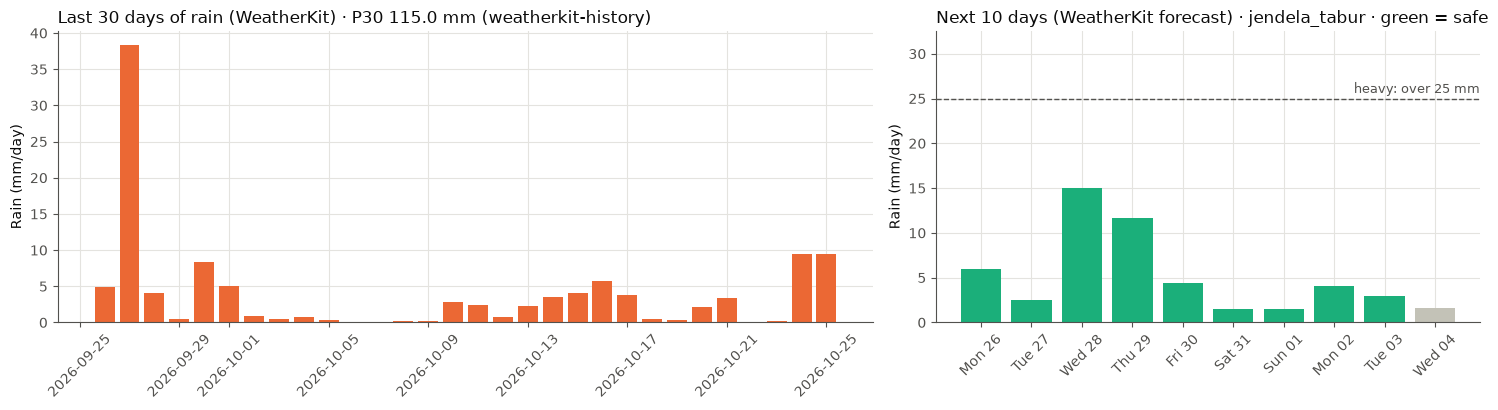

In [7]:
fig, (ax_p30, ax_fc) = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
recent = wk_recent[wk_recent.index >= TODAY - timedelta(days=30)]
ax_p30.bar(recent.index, recent.values, color=kw.WK_COLOR, width=0.8)
p30_text = "P30 unknown" if p30["p30_mm"] is None else f"P30 {p30['p30_mm']} mm ({p30['p30_source']})"
ax_p30.set_title(f"Last 30 days of rain (WeatherKit) · {p30_text}" + (" · water stress" if water_stress else ""),
                 loc="left")
ax_p30.set_ylabel("Rain (mm/day)")
ax_p30.tick_params(axis="x", rotation=45)

colors = [kw.THIRD_COLOR if d in safe_days else kw.REMOVED for d in forecast_df["date"]]
fc_rain = forecast_df["rain_mm"].astype(float)  # a missing amount draws no bar, never 0 mm
ax_fc.bar([f"{d:%a %d}" for d in forecast_df["date"]], fc_rain, color=colors)
ax_fc.set_ylim(0, max(rules.HEAVY_RAIN_MM * 1.3, fc_rain.max() * 1.2))
kw.threshold_line(ax_fc, rules.HEAVY_RAIN_MM, f"heavy: over {rules.HEAVY_RAIN_MM:.0f} mm")
ax_fc.set_title(f"Next 10 days (WeatherKit forecast) · {l8['l8_state']} · green = safe", loc="left")
ax_fc.set_ylabel("Rain (mm/day)")
ax_fc.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(OUTPUT_RAIN_PLOT, dpi=150, bbox_inches="tight")
plt.show()

## 5. This round: what to spread, and on which day
**What:** one round is the annual dose ÷ `ROUNDS_PER_YEAR`. Mg goes first, N on a later safe day, never mixed:

- **Mg** on the first safe day.
- **N** on the first safe day at least `MIN_DAYS_MG_TO_N` days later, and that gap depends on the Mg product:
  - **after dolomite, 14 days.** That is longer than the 10-day forecast, so N gets a "not before" date: run this
    notebook again then for a safe day.
  - **after kieserite, 1 day:** the next safe day.

**Why dolomite needs the gap.** Dolomite is a lime. It raises the soil pH around its particles, and at higher pH urea
and ammonium N turn into ammonia gas and are lost to the air. In a field trial, every tonne of dolomitic lime per
hectare raised the ammonia loss from urea by 1.7–2.2 percentage points. Urea's losses peak in the first week, and
dolomite spread weeks *after* urea still raised the loss. Kieserite (MgSO4) doesn't change the pH.

**How sure the 14 days is.** The mechanism is peer-reviewed; the number isn't. Extension and industry pages say at
least 2 weeks, and an Indonesian dolomite producer says 21–28 days for urea and ZA. No PPKS or MPOB guideline was
found. An agronomist should confirm it.

Sources (checked 26 Oct 2026):
- [Liming and enhanced-efficiency N fertilizers: ammonia volatilization losses from subtropical no-till (RBCS)](https://www.rbcsjournal.org/article/liming-and-enhanced-efficiency-nitrogen-fertilizers-ammonia-volatilization-losses-from-subtropical-no-till/)
- [Ammonia volatilization following soil application of conventional urea or urea with urease inhibitor (RBCS)](https://www.rbcsjournal.org/article/ammonia-volatilization-following-soil-application-of-conventional-urea-or-urea-with-urease-inhibitor/)
- [Ammonia volatilization from frequently applied fertilizers for the low-country tea soils of Sri Lanka](https://www.researchgate.net/publication/277952246_Ammonia_volatilization_from_frequently_applied_fertilizers_for_the_low-country_tea_growing_soils_of_Sri_Lanka)
- [Liming acid soils with dolomite for oil palm (Chemiseed)](https://chemiseed.com/en-id/blogs/cover-crops-seeds/liming-acid-soils-dolomite-oil-palm-malaysia-ph-calcium-magnesium): "at least 2 weeks between lime and nitrogen"
- [Jarak pemberian dolomit dengan pupuk lain pada sawit (pabrikpupukdolomit.com)](https://pabrikpupukdolomit.com/jarak-pemberian-dolomit-dengan-pupuk-lain-pada-sawit/): 21–28 days for urea and ZA

Both products are listed for each nutrient: the amounts are alternatives, pick one per nutrient. If L5 or L8 says
wait, the amounts stay and the date becomes the reason to wait, in the same spirit as the team's flag-only gate.

**In:** `zones`, `products`, `safe_days`, `l8`, `water_stress` · **Out:** `plan` (one row per zone, nutrient and
product), saved as `oil_palm_spreading_plan.csv` together with part 6.

In [8]:
def assign_days(window, min_gap):
    """(Mg day, N day) from the safe days; N is None when no safe day is min_gap days after Mg (wait)."""
    if not window:
        return None, None
    mg_day = window[0]
    later = [d for d in window if (d - mg_day).days >= min_gap]
    return mg_day, (later[0] if later else None)


_d = [TODAY + timedelta(days=i) for i in range(10)]
assert assign_days(_d, 1) == (_d[0], _d[1])        # kieserite: the next safe day
assert assign_days(_d, 14) == (_d[0], None)        # dolomite: 14 days is past a 10-day forecast
assert assign_days([_d[0], _d[5]], 3) == (_d[0], _d[5])
assert assign_days(_d[:1], 1) == (_d[0], None)     # one safe day: N waits
assert assign_days([], 1) == (None, None)

WAIT_REASONS = {
    "tunda": f"wait: {MONTHS[TODAY.month - 1]} is a tunda month (avg {l8['month_gate']['avg_mm']:.0f} mm)",
    "cek": f"check soil and weather first: {MONTHS[TODAY.month - 1]} averages {l8['month_gate']['avg_mm']:.0f} mm",
    "cek_hujan": "wait: no safe day in the 10-day forecast",
}
if l8["l8_state"] in WAIT_REASONS:
    wait = WAIT_REASONS[l8["l8_state"]]
elif water_stress:
    wait = f"wait for rain: P30 {p30['p30_mm']} mm, under {rules.P30_THRESHOLD_MM:.0f} mm"
else:
    wait = None
MG_PRODUCTS = {"kieserite": "kieserite_Mg_expensive", "dolomite": "dolomite_Mg_cheaper"}


def when(nutrient, product, mg_choice):
    """The date (or reason to wait) for one row, if Mg is spread as `mg_choice`."""
    if nutrient == "Mg" and product != MG_PRODUCTS[mg_choice]:
        return "—"
    if wait:
        return wait
    gap = MIN_DAYS_MG_TO_N[MG_PRODUCTS[mg_choice]]
    mg_day, n_day = assign_days(safe_days, gap)
    if nutrient == "Mg":
        return f"{mg_day:%a %d %b %Y}"
    if n_day:
        return f"{n_day:%a %d %b %Y}"
    return f"not before {mg_day + timedelta(days=gap):%a %d %b %Y}: run this notebook again then"


plan = products.assign(
    round="this round",
    kg_per_zone=products["product_kg_per_zone_per_year"] / ROUNDS_PER_YEAR,
    kg_per_palm=products["product_kg_per_palm_per_year"] / ROUNDS_PER_YEAR,
    when_if_mg_is_kieserite=[when(n, p, "kieserite") for n, p in zip(products["nutrient"], products["product"])],
    when_if_mg_is_dolomite=[when(n, p, "dolomite") for n, p in zip(products["nutrient"], products["product"])],
)[["zone", "round", "nutrient", "product", "kg_per_zone", "kg_per_palm", "when_if_mg_is_kieserite",
   "when_if_mg_is_dolomite"]]
print(f"Round dose = annual ÷ {ROUNDS_PER_YEAR}.")
for choice, product in MG_PRODUCTS.items():
    print(f"  Mg as {choice}: Mg {when('Mg', product, choice)} · N {when('N', None, choice)}")
print()
display(plan.set_index(["zone", "nutrient", "product"]).drop(columns="round")
        .style.format({"kg_per_zone": "{:.2f}", "kg_per_palm": "{:.3f}"}))
print("\nProduct notes (GUESS – no source yet):")
for name, note in PRODUCT_NOTES.items():
    print(f"  {name}: {note}")

Round dose = annual ÷ 2.
  Mg as kieserite: Mg Mon 26 Oct 2026 · N Tue 27 Oct 2026
  Mg as dolomite: Mg Mon 26 Oct 2026 · N not before Mon 09 Nov 2026: run this notebook again then




Product notes (GUESS – no source yet):
  kieserite_Mg_expensive: Kieserite (MgSO4): water-soluble, acts within weeks; the faster Mg option.
  dolomite_Mg_cheaper: Dolomite (Ca/Mg carbonate): slow, also raises soil pH (suits acid soils); spread N at least 14 days after it (MIN_DAYS_MG_TO_N), never together.
  ZA_N_cheaper: ZA (ammonium sulfate): acidifies the soil over time; next to fresh dolomite its ammonium is lost to the air as well.
  urea_N_expensive: Urea: highest N content, but loses N to the air on hot, dry soil left uncovered, and more on soil limed with dolomite; spread on moist soil before light rain.


## 6. The year: when do the two rounds go?
**What:** the two rounds go in two `open` months `ROUND_GAP_MONTHS` apart. Among the pairs that qualify, the one with
the highest combined in-band share wins: the months that most often get 100–200 mm, the band the proposal names as
best. GUESS – no source yet: the rule for picking months is this notebook's.

This is a plan from climate averages. The actual dates always come from part 4, run in that month.

**In:** `month_table` · **Out:** `round_months`, the calendar figure, and the yearly rows of the plan.

Open-month pairs and their combined in-band share:
  Jan + Jul: 83%
  Feb + Aug: 93%
  Mar + Sep: 97%  ← chosen
  Apr + Oct: 77%
  May + Nov: 50%

Per round, whole photo (5 zones), pick one product per nutrient:
  Mg: dolomite_Mg_cheaper        1.77 kg
  Mg: kieserite_Mg_expensive     1.52 kg
  N: ZA_N_cheaper               7.35 kg
  N: urea_N_expensive           3.36 kg


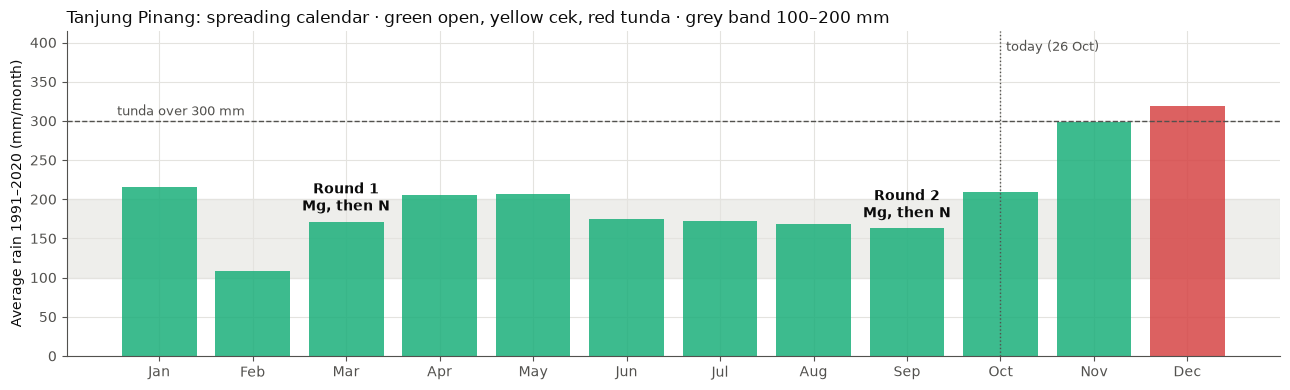

In [9]:
pairs = sorted({tuple(sorted((m, (m + ROUND_GAP_MONTHS - 1) % 12 + 1))) for m in range(1, 13)})
open_pairs = [p for p in pairs if all(month_table.iloc[m - 1]["gate"] == "open" for m in p)]
if not open_pairs:
    raise RuntimeError(f"No two open months {ROUND_GAP_MONTHS} months apart: the calendar rule needs a decision")
round_months = max(open_pairs, key=lambda p: sum(month_table.iloc[m - 1]["in_band_share"] for m in p))
print("Open-month pairs and their combined in-band share:")
for p in open_pairs:
    share = sum(month_table.iloc[m - 1]["in_band_share"] for m in p)
    print(f"  {MONTHS[p[0] - 1]} + {MONTHS[p[1] - 1]}: {share:.0%}" + ("  ← chosen" if p == round_months else ""))

totals = products.groupby(["nutrient", "product"])["product_kg_per_zone_per_year"].sum() / ROUNDS_PER_YEAR
print(f"\nPer round, whole photo ({len(zones)} zones), pick one product per nutrient:")
for (nutrient, product), kg in totals.items():
    print(f"  {nutrient}: {product:<24} {kg:6.2f} kg")

gate_colors = {"open": kw.THIRD_COLOR, "cek": "#f2b134", "tunda": "#d64545"}
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(MONTHS, month_table["avg_mm"], color=[gate_colors[g] for g in month_table["gate"]], alpha=0.85)
ax.axhspan(100, 200, color=kw.GRID, alpha=0.6, zorder=0)
kw.threshold_line(ax, rules.GATE_TUNDA_ABOVE_MM, "tunda over 300 mm", x=-0.45)
for i, m in enumerate(round_months, start=1):
    ax.annotate(f"Round {i}\nMg, then N", (m - 1, month_table.iloc[m - 1]["avg_mm"]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontweight="bold")
ax.set_ylim(0, max(month_table["avg_mm"].max(), 300) * 1.3)
ax.axvline(TODAY.month - 1, color=kw.MUTED, linestyle=":", linewidth=1)
ax.annotate(f"today ({TODAY:%d %b})", (TODAY.month - 1, ax.get_ylim()[1]), xytext=(4, -14),
            textcoords="offset points", color=kw.MUTED, fontsize=9)
ax.set_ylabel(f"Average rain {NORMAL_PERIOD[0]}–{NORMAL_PERIOD[1]} (mm/month)")
ax.set_title(f"{SITE_NAME}: spreading calendar · green open, yellow cek, red tunda · grey band 100–200 mm", loc="left")
fig.tight_layout()
fig.savefig(OUTPUT_CALENDAR_PLOT, dpi=150, bbox_inches="tight")
plt.show()

## 7. Save the plan
**Out:** `oil_palm_spreading_plan.csv`: one row per zone, round, nutrient and product, with kg per zone, kg per palm,
and the date or the reason to wait. The yearly rounds carry their month. Like every `oil_palm_*` file, it is
gitignored.

In [10]:
yearly = pd.concat([products.assign(
    round=f"round {i}",
    kg_per_zone=products["product_kg_per_zone_per_year"] / ROUNDS_PER_YEAR,
    kg_per_palm=products["product_kg_per_palm_per_year"] / ROUNDS_PER_YEAR,
    when_if_mg_is_kieserite=[("—" if p == MG_PRODUCTS["dolomite"] else
                              f"{MONTHS[m - 1]} (climate plan; dates from part 4 that month)") for p in products["product"]],
    when_if_mg_is_dolomite=[("—" if p == MG_PRODUCTS["kieserite"] else
                             f"{MONTHS[m - 1]} (climate plan; N at least {MIN_DAYS_MG_TO_N[MG_PRODUCTS['dolomite']]} "
                             "days after the dolomite)") for p in products["product"]],
)[plan.columns] for i, m in enumerate(round_months, start=1)])
full_plan = pd.concat([plan, yearly], ignore_index=True)
full_plan.to_csv(OUTPUT_PLAN_CSV, index=False)

for nutrient in ("Mg", "N"):  # every round's elemental total adds up to the integration run's annual dose
    rounds_kg = (full_plan[(full_plan["nutrient"] == nutrient) & full_plan["round"].str.startswith("round")]
                 .merge(products[["zone", "product", "label_nutrient_fraction"]], on=["zone", "product"])
                 .eval("kg_per_zone * label_nutrient_fraction").sum() / 2)  # two products per nutrient: alternatives
    assert abs(rounds_kg - zones[f"{nutrient} kg/year"].sum()) < 1e-6, (nutrient, rounds_kg)
print(f"Saved {OUTPUT_PLAN_CSV}: {len(full_plan)} rows · {OUTPUT_RAIN_PLOT} · {OUTPUT_CALENDAR_PLOT}")

Saved oil_palm_spreading_plan.csv: 60 rows · oil_palm_spreading_rain.png · oil_palm_spreading_calendar.png
